# Exploratory Analysis

## Objective

This notebook explores the relationship between CMS Medical Care performance and enrollee-reported health plan experience.

**Primary question:** Are stronger Medical Care quality ratings associated with better enrollee-reported health plan experiences?

The analysis reviews the target distribution, group-level experience by Medical Care rating, and the relationship between continuous Medical Care scores and enrollee experience.


## 1. Load the Analysis-Ready Dataset

In [1]:
import pandas as pd
from pathlib import Path

project_root = Path("..")
data_clean = project_root / "data_clean"

analysis_file = data_clean / "cms_qrs_enrollee_experience_clean.csv"

df = pd.read_csv(analysis_file)

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (308, 22)


,REPORTING_UNIT_ID,Issuer_Id,State,Plan_Type,Global_rate,Global_score,S1_rate,S1_score,S2_rate,S2_score,S3_rate,S3_score,N_COMPLETED_SURVEYS,RESPONSE_RATE,RATE_HP_SCORE_ADJ,RATE_HEALTH_CARE_SCORE_ADJ,GETCAREQUICK_SCORE_ADJ,GETNEEDEDCARE_SCORE_ADJ,CUSTOMERSERVICE_SCORE_ADJ,EXPERIENCEWITHCOST_SCORE_ADJ,CARECOORD_SCORE_ADJ,ACCESSINFO_SCORE_ADJ
0,10091-OR-PPO,10091,OR,PPO,4,81.860,3.0,77.383,4,88.955,5,92.677,150,20.1%,74.03,78.31,61.23,63.77,80.62,77.66,82.60,55.32
1,10207-VA-HMO,10207,VA,HMO,5,90.341,5.0,91.638,5,95.263,4,80.227,187,15.7%,74.36,82.88,75.19,73.08,70.08,80.86,82.49,48.13
2,11177-NY-HMO,11177,NY,HMO,4,83.801,4.0,83.349,CSR-I,CSR-I,4,85.607,98,16.1%,67.21,77.55,69.28,63.51,70.29,73.72,81.67,45.33
3,11269-WY-PPO,11269,WY,PPO,2,67.476,2.0,64.036,CSR-I,CSR-I,4,81.241,117,16.7%,76.58,83.22,77.04,75.05,79.75,75.42,84.04,46.28
4,11512-NC-EPO,11512,NC,EPO,4,83.318,3.0,79.517,5,95.010,4,86.835,204,13.4%,69.99,80.13,76.21,75.22,70.18,73.18,81.95,46.29


## 2. Confirm Analytical Variables

In [2]:
analysis_vars = [
    "S1_rate",
    "S1_score",
    "RATE_HP_SCORE_ADJ"
]

display(df[analysis_vars].dtypes)
display(df[analysis_vars].describe())


S1_rate              float64
S1_score             float64
RATE_HP_SCORE_ADJ    float64
dtype: object

,S1_rate,S1_score,RATE_HP_SCORE_ADJ
count,308.000000,308.000000,308.000000
mean,3.103896,76.144182,71.590974
std,0.966331,9.620962,5.448715
min,1.000000,50.203000,50.540000
25%,2.000000,69.169000,68.325000
50%,3.000000,76.790000,71.325000
75%,4.000000,83.381000,74.650000
max,5.000000,100.931000,86.200000


In [3]:
print("Medical Care rating distribution:")
print(
    df["S1_rate"]
    .value_counts()
    .sort_index()
)


Medical Care rating distribution:
S1_rate
1.0     14
2.0     69
3.0    114
4.0     93
5.0     18
Name: count, dtype: int64


## 3. Distribution of Enrollee Experience

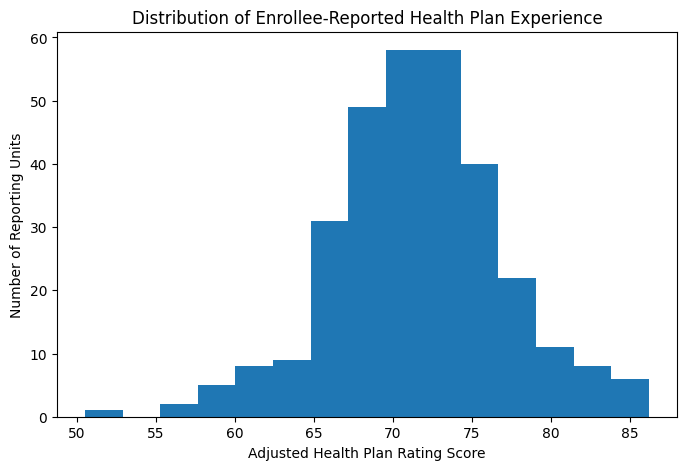

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(df["RATE_HP_SCORE_ADJ"], bins=15)

plt.xlabel("Adjusted Health Plan Rating Score")
plt.ylabel("Number of Reporting Units")
plt.title("Distribution of Enrollee-Reported Health Plan Experience")

plt.show()


In [5]:
# Measure skewness of the target variable
experience_skew = df["RATE_HP_SCORE_ADJ"].skew()

print("Health Plan Rating skewness:", round(experience_skew, 3))


Health Plan Rating skewness: -0.151


## 4. Enrollee Experience by Medical Care Rating

In [6]:
# Summarize enrollee experience by Medical Care star rating
rating_summary = (
    df.groupby("S1_rate")["RATE_HP_SCORE_ADJ"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(2)
)

display(rating_summary)


,count,mean,median,std,min,max
S1_rate,,,,,,
1.0,14,73.76,74.40,4.99,62.33,82.49
2.0,69,73.43,73.02,5.47,63.05,86.20
3.0,114,71.08,71.20,5.56,50.54,83.89
4.0,93,70.17,69.98,4.93,55.48,85.68
5.0,18,73.45,74.44,5.15,65.86,81.47


In [7]:
# Average Health Plan Rating by Medical Care star level
mean_experience = (
    df.groupby("S1_rate")["RATE_HP_SCORE_ADJ"]
    .mean()
    .round(2)
)

display(mean_experience)


S1_rate
1.0    73.76
2.0    73.43
3.0    71.08
4.0    70.17
5.0    73.45
Name: RATE_HP_SCORE_ADJ, dtype: float64

### Group-Level Finding

Average enrollee experience did not increase consistently as Medical Care star ratings increased. The pattern was non-linear across the 1-to-5-star categories.


## 5. Correlation Analysis

In [8]:
# Pearson correlation
pearson_corr = df["S1_score"].corr(df["RATE_HP_SCORE_ADJ"], method="pearson")

# Spearman correlation
spearman_corr = df["S1_score"].corr(df["RATE_HP_SCORE_ADJ"], method="spearman")

print("Pearson correlation:", round(pearson_corr, 3))
print("Spearman correlation:", round(spearman_corr, 3))


Pearson correlation: -0.132
Spearman correlation: -0.159


### Correlation Findings

Medical Care Score showed a weak negative relationship with adjusted Health Plan Experience Score.

- Pearson correlation: -0.132
- Spearman correlation: -0.159

Both measures suggest that higher Medical Care performance was not associated with better enrollee-reported experience in this sample. The relationship was weak, indicating that Medical Care performance alone explains little of the variation in member experience.
